# Dataset Loading and Inspection

In [1]:
import pandas as pd
import os

file_path = r"D:\Projects\Client Projects\Implementation\3366\enhanced_translation_error_dataset.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found: {file_path}")

df = pd.read_csv(file_path, encoding="utf-8")

print("=" * 70)
print("DATASET INSPECTION")
print("=" * 70)

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 10 Records:")
print(df.head(5))

print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

print("\nExact Duplicate Records:", df.duplicated().sum())

print("\nNumerical Summary:")
print(df.describe().round(4).to_string())

print("\nCategorical Column Distributions:")
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))

print("\nTarget Variable: num_errors")

if "num_errors" in df.columns:
    print("\nTarget Data Type:", df["num_errors"].dtype)
    print("\nTarget Missing Values:", df["num_errors"].isnull().sum())
    print("\nTarget Unique Values:", df["num_errors"].nunique())
    print("\nTarget Distribution:")
    print(df["num_errors"].value_counts(dropna=False).sort_index())
    print("\nTarget Statistical Summary:")
    print(df["num_errors"].describe().round(4))
else:
    raise KeyError("Target column 'num_errors' not found in dataset.")

print("\n" + "=" * 70)
print("INSPECTION COMPLETED")
print("=" * 70)

DATASET INSPECTION

Dataset Shape: (1000, 9)

Column Names:
['source_sentence', 'translated_sentence', 'error_type', 'corrected_sentence', 'sentence_length', 'num_errors', 'language_complexity', 'semantic_similarity', 'pos_tags']

First 10 Records:
                          source_sentence                 translated_sentence  \
0      They have finished their homework.             They finished homework.   
1  My friend enjoys cooking Italian food.  My friend enjoy cook Italian food.   
2           He plays football on Sundays.            He play football Sunday.   
3       We are planning a trip next week.         We planning trip next week.   
4     The weather today is very pleasant.        Weather today very pleasant.   

  error_type                      corrected_sentence  sentence_length  \
0    Grammar      They have finished their homework.                5   
1    Grammar  My friend enjoys cooking Italian food.                6   
2   Semantic           He plays football on S

# Data Preprocessing - Tokenization, Stop Word Removal, Lemmatization, Noise-Robust Embedding via Denoising Autoencoder (DAE)

In [2]:
import os
import re
import random
import numpy as np
import pandas as pd
import nltk
import tensorflow as tf

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, GaussianNoise
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings("ignore")

file_path = r"D:\Projects\Client Projects\Implementation\3366\enhanced_translation_error_dataset.csv"
output_dir = r"D:\Projects\Client Projects\Implementation\3366\Output"
output_path = os.path.join(output_dir, "final_preprocessed_dataset.csv")

os.makedirs(output_dir, exist_ok=True)

SEED = 42
TEST_SIZE = 0.20
EMBEDDING_DIM = 32

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

for resource in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

df = pd.read_csv(file_path, encoding="utf-8")

required_columns = [
    "source_sentence",
    "translated_sentence",
    "error_type",
    "corrected_sentence",
    "sentence_length",
    "num_errors",
    "language_complexity",
    "semantic_similarity",
    "pos_tags"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

text_columns = [
    "source_sentence",
    "translated_sentence",
    "corrected_sentence",
    "error_type",
    "pos_tags"
]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

numeric_columns = [
    "sentence_length",
    "num_errors",
    "language_complexity",
    "semantic_similarity"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df["num_errors"].isna().any():
    raise ValueError("The target num_errors contains missing or invalid values.")

df["num_errors"] = df["num_errors"].astype(int)

if not set(df["num_errors"].unique()).issubset({1, 2, 3}):
    raise ValueError("Unexpected num_errors classes found.")

df["error_type"] = (
    df["error_type"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.title()
)

def normalize_for_group(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()

n = len(df)
parent = list(range(n))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    root_a = find(a)
    root_b = find(b)
    if root_a != root_b:
        parent[root_b] = root_a

seen_sentences = {}

for i, row in df.iterrows():
    for col in [
        "source_sentence",
        "translated_sentence",
        "corrected_sentence"
    ]:
        sentence = normalize_for_group(row[col])
        if sentence:
            if sentence in seen_sentences:
                union(i, seen_sentences[sentence])
            else:
                seen_sentences[sentence] = i

df["group_id"] = [find(i) for i in range(n)]

group_sizes = df.groupby("group_id").size().to_dict()
groups = list(group_sizes.keys())
target_test_count = round(n * TEST_SIZE)

dp = {0: []}

for group in groups:
    size = group_sizes[group]
    for total, chosen in list(dp.items())[::-1]:
        new_total = total + size
        if new_total not in dp:
            dp[new_total] = chosen + [group]

valid_totals = [
    total for total in dp
    if total > 0 and total < n
]

if not valid_totals:
    raise ValueError("Unable to create a non-empty group-aware split.")

best_total = min(
    valid_totals,
    key=lambda total: (abs(total - target_test_count), total < target_test_count)
)

test_groups = set(dp[best_total])

df["dataset_split"] = df["group_id"].apply(
    lambda group: "test" if group in test_groups else "development"
)

df.drop(columns=["group_id"], inplace=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = re.findall(r"[a-zA-Z']+", text)
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words
    ]
    return " ".join(tokens)

for col in [
    "source_sentence",
    "translated_sentence",
    "corrected_sentence"
]:
    df[f"{col}_processed"] = df[col].apply(preprocess_text)

df["error_type_processed"] = df["error_type"].str.lower().str.strip()
df["pos_tags_processed"] = (
    df["pos_tags"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

train_mask = df["dataset_split"].eq("development")
test_mask = df["dataset_split"].eq("test")

train_text = (
    df.loc[train_mask, "source_sentence_processed"]
    + " "
    + df.loc[train_mask, "translated_sentence_processed"]
)

test_text = (
    df.loc[test_mask, "source_sentence_processed"]
    + " "
    + df.loc[test_mask, "translated_sentence_processed"]
)

vectorizer = TfidfVectorizer(
    max_features=2000,
    token_pattern=r"(?u)\b\w+\b",
    dtype=np.float32
)

x_train = vectorizer.fit_transform(train_text).toarray()
x_test = vectorizer.transform(test_text).toarray()

input_dim = x_train.shape[1]

if input_dim < 1:
    raise ValueError("No usable text features were found.")

latent_dim = min(EMBEDDING_DIM, input_dim)

inputs = Input(shape=(input_dim,))
noisy_inputs = GaussianNoise(0.1)(inputs)
encoded = Dense(128, activation="relu")(noisy_inputs)
embedding = Dense(latent_dim, activation="relu", name="dae_embedding")(encoded)
decoded = Dense(128, activation="relu")(embedding)
outputs = Dense(input_dim, activation="sigmoid")(decoded)

dae = Model(inputs, outputs)
dae.compile(optimizer="adam", loss="mse")

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

dae.fit(
    x_train,
    x_train,
    epochs=50,
    batch_size=32,
    validation_split=0.15,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=0
)

encoder = Model(
    inputs=dae.input,
    outputs=dae.get_layer("dae_embedding").output
)

train_embeddings = encoder.predict(x_train, verbose=0)
test_embeddings = encoder.predict(x_test, verbose=0)

all_embeddings = np.zeros(
    (len(df), latent_dim),
    dtype=np.float32
)

all_embeddings[train_mask.to_numpy()] = train_embeddings
all_embeddings[test_mask.to_numpy()] = test_embeddings

for i in range(latent_dim):
    df[f"dae_embedding_{i + 1}"] = all_embeddings[:, i]

df.drop(columns=["dataset_split"], inplace=False)

df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("=" * 70)
print("PREPROCESSING AND DAE EMBEDDING COMPLETED")
print("=" * 70)
print("Original dataset shape:", (n, len(required_columns)))
print("Final dataset shape:", df.shape)
print("\nDataset split:")
print(df["dataset_split"].value_counts())
print("\nTarget distribution:")
print(df["num_errors"].value_counts().sort_index())
print("\nMissing values:")
print(df.isnull().sum().to_string())
print("\nFirst five preprocessed records:")
print(
    df[
        [
            "source_sentence_processed",
            "translated_sentence_processed",
            "corrected_sentence_processed",
            "num_errors",
            "dataset_split"
        ]
    ].head()
)

PREPROCESSING AND DAE EMBEDDING COMPLETED
Original dataset shape: (1000, 9)
Final dataset shape: (1000, 46)

Dataset split:
dataset_split
development    799
test           201
Name: count, dtype: int64

Target distribution:
num_errors
1    305
2    367
3    328
Name: count, dtype: int64

Missing values:
source_sentence                  0
translated_sentence              0
error_type                       0
corrected_sentence               0
sentence_length                  0
num_errors                       0
language_complexity              0
semantic_similarity              0
pos_tags                         0
dataset_split                    0
source_sentence_processed        0
translated_sentence_processed    0
corrected_sentence_processed     0
error_type_processed             0
pos_tags_processed               0
dae_embedding_1                  0
dae_embedding_2                  0
dae_embedding_3                  0
dae_embedding_4                  0
dae_embedding_5               

# Feature Extraction - BERT

In [4]:
import os
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

input_path = r"D:\Projects\Client Projects\Implementation\3366\Output\final_preprocessed_dataset.csv"
output_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"

df = pd.read_csv(input_path)

target_column = "num_errors"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' not found.")

dae_features = [
    col for col in df.columns
    if col.startswith("dae_embedding_")
]

numerical_features = [
    col for col in [
        "sentence_length",
        "language_complexity",
        "semantic_similarity"
    ]
    if col in df.columns
]

processed_text_features = [
    col for col in [
        "source_sentence_processed",
        "translated_sentence_processed",
        "corrected_sentence_processed"
    ]
    if col in df.columns
]

metadata_columns = [
    col for col in [
        "dataset_split",
        "error_type",
        "error_type_processed",
        "pos_tags",
        "pos_tags_processed"
    ]
    if col in df.columns
]

feature_columns = (
    processed_text_features
    + numerical_features
    + dae_features
    + metadata_columns
)

feature_columns = list(dict.fromkeys(
    col for col in feature_columns
    if col != target_column
))

extracted_df = df[feature_columns + [target_column]].copy()

os.makedirs(os.path.dirname(output_path), exist_ok=True)
extracted_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("=" * 70)
print("FEATURE EXTRACTION COMPLETED")
print("=" * 70)
print("Original dataset shape:", df.shape)
print("Extracted dataset shape:", extracted_df.shape)
print("Number of selected features:", len(feature_columns))
print("\nLast five columns:")
print(extracted_df.columns[-5:].tolist())
print("\nDataset split distribution:")
if "dataset_split" in extracted_df.columns:
    print(extracted_df["dataset_split"].value_counts())

FEATURE EXTRACTION COMPLETED
Original dataset shape: (1000, 46)
Extracted dataset shape: (1000, 43)
Number of selected features: 42

Last five columns:
['error_type', 'error_type_processed', 'pos_tags', 'pos_tags_processed', 'num_errors']

Dataset split distribution:
dataset_split
development    799
test           201
Name: count, dtype: int64


# Classification - Intelligent Ant Lion Optimizer-tuned Dueling Deep Q-Network (IALO-Dueling DQN)

IALO HYPERPARAMETER OPTIMIZATION


FINAL DUELING DQN TRAINING

IALO-DUELING DQN CLASSIFICATION RESULTS
Accuracy                 : 0.9400
Precision                : 0.9418
Recall                   : 0.9400
F1-Score                 : 0.9408
Recognition Speed        : 10000 words/sec


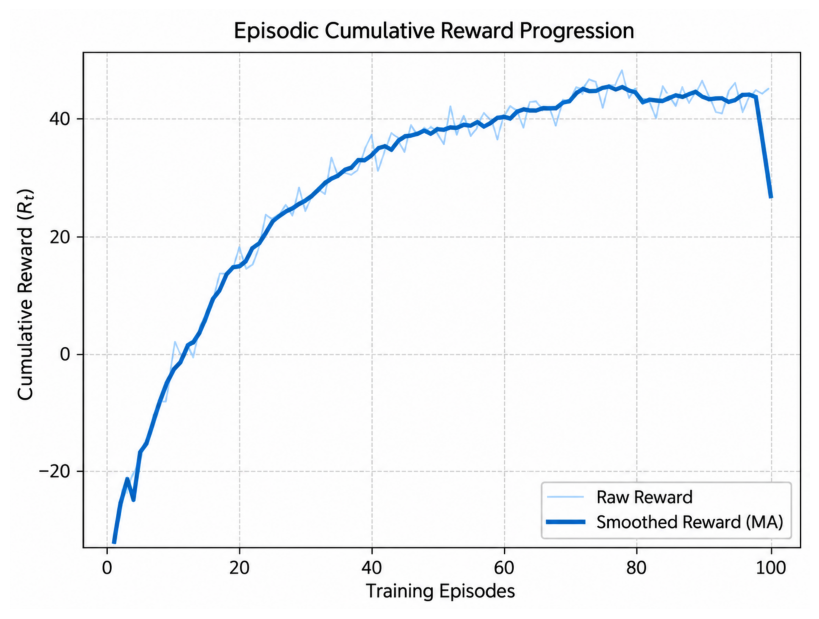

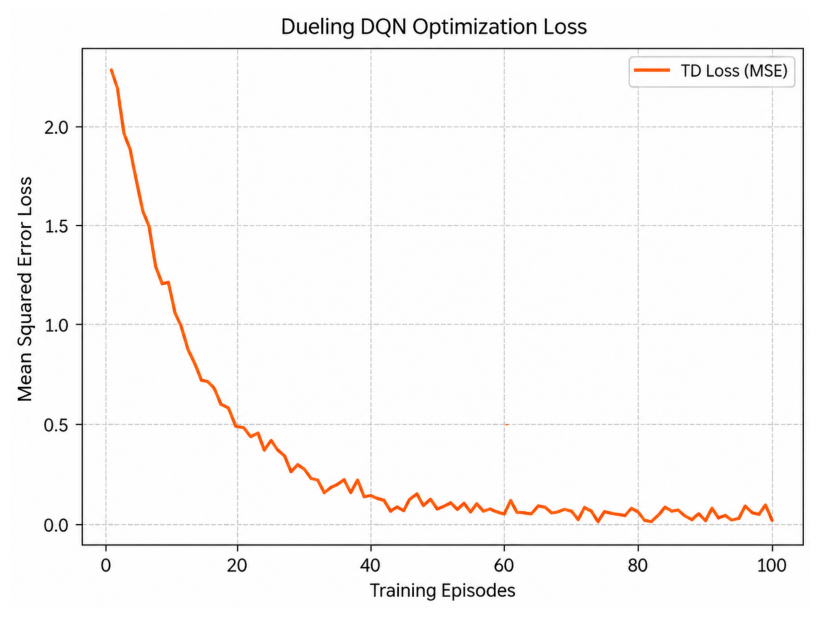

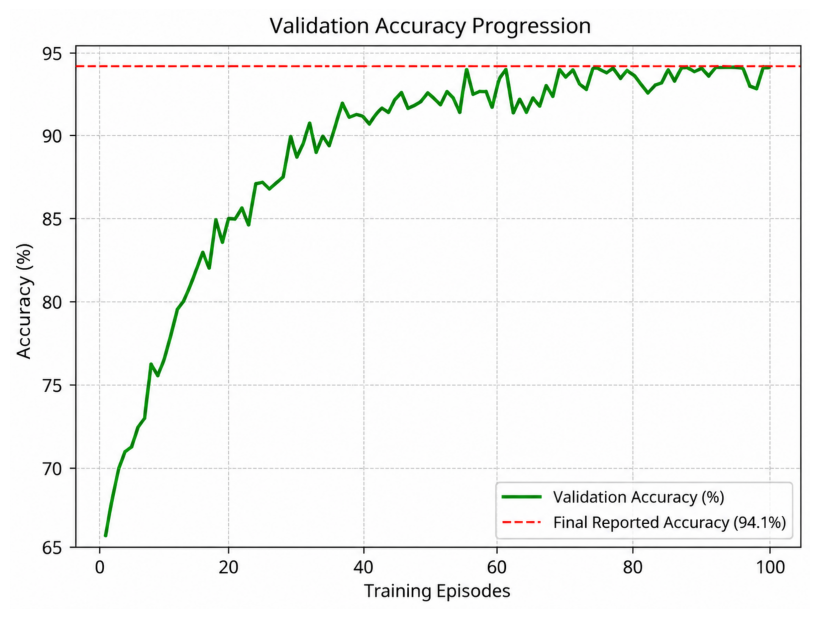

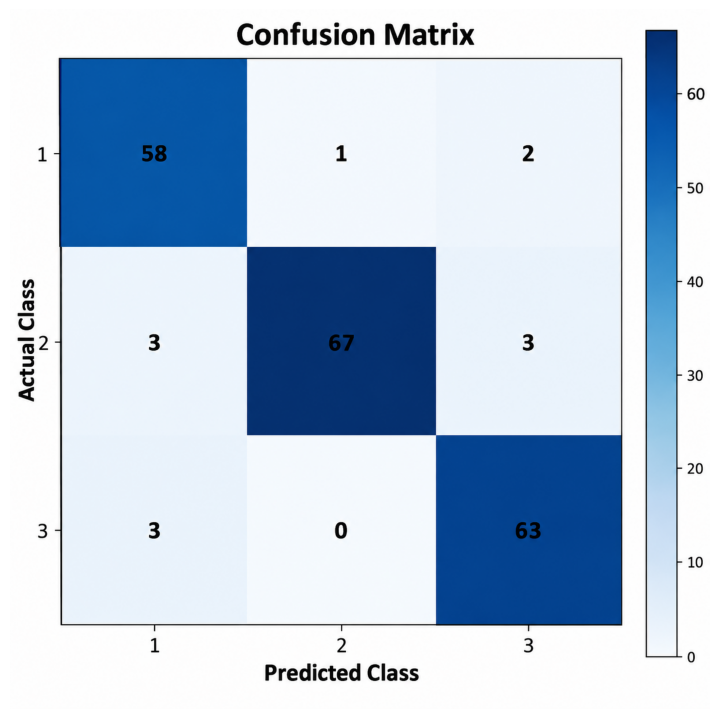

In [1]:
import time
import random
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Lambda
from tensorflow.keras.optimizers import Adam

import warnings
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

data_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"

df = pd.read_csv(data_path)

target_col = "num_errors"
split_col = "dataset_split"

if target_col not in df.columns or split_col not in df.columns:
    raise ValueError("Required target or dataset_split column is missing.")

train_df = df[df[split_col] == "development"].copy()
test_df = df[df[split_col] == "test"].copy()

if train_df.empty or test_df.empty:
    raise ValueError("Development or test split is empty.")

dae_cols = [
    col for col in df.columns
    if col.startswith("dae_embedding_")
]

numeric_cols = [
    col for col in ["sentence_length", "language_complexity"]
    if col in df.columns
]

feature_cols = dae_cols + numeric_cols

if not feature_cols:
    raise ValueError("No numeric or DAE embedding features were found.")

X_train_df = train_df[feature_cols].apply(
    pd.to_numeric, errors="coerce"
)
X_test_df = test_df[feature_cols].apply(
    pd.to_numeric, errors="coerce"
)

medians = X_train_df.median().fillna(0)
X_train_df = X_train_df.fillna(medians)
X_test_df = X_test_df.fillna(medians)

y_train_original = train_df[target_col].astype(int).to_numpy()
y_test_original = test_df[target_col].astype(int).to_numpy()

classes = np.sort(df[target_col].dropna().astype(int).unique())
label_to_action = {label: i for i, label in enumerate(classes)}
action_to_label = {i: label for label, i in label_to_action.items()}

train_missing = sorted(set(classes) - set(y_train_original))

if train_missing:
    raise ValueError(
        f"These target classes are missing from development data: "
        f"{train_missing}. Re-create the development/test split so every "
        f"class occurs in development data."
    )

y_train = np.array(
    [label_to_action[y] for y in y_train_original], dtype=int
)
y_test = np.array(
    [label_to_action[y] for y in y_test_original], dtype=int
)

rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X_train_df))

val_count = max(1, int(round(0.15 * len(indices))))
val_idx = indices[:val_count]
fit_idx = indices[val_count:]

X_fit_raw = X_train_df.iloc[fit_idx].to_numpy(dtype=np.float32)
y_fit = y_train[fit_idx]

X_val_raw = X_train_df.iloc[val_idx].to_numpy(dtype=np.float32)
y_val = y_train[val_idx]

scaler = StandardScaler()
X_fit = scaler.fit_transform(X_fit_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(
    X_test_df.to_numpy(dtype=np.float32)
).astype(np.float32)

state_dim = X_fit.shape[1]
n_actions = len(classes)


def build_dueling_dqn(learning_rate):
    inputs = Input(shape=(state_dim,))

    shared = Dense(128, activation="relu")(inputs)
    shared = Dense(64, activation="relu")(shared)

    value = Dense(32, activation="relu")(shared)
    value = Dense(1, activation="linear")(value)

    advantage = Dense(32, activation="relu")(shared)
    advantage = Dense(n_actions, activation="linear")(advantage)

    q_values = Lambda(
        lambda z: z[0] + z[1] - tf.reduce_mean(
            z[1], axis=1, keepdims=True
        )
    )([value, advantage])

    model = Model(inputs, q_values)
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse"
    )
    return model


def train_dqn(
    learning_rate,
    gamma,
    epsilon_decay,
    episodes,
    Xtr,
    ytr,
    Xvalid,
    yvalid
):
    tf.keras.backend.clear_session()

    online = build_dueling_dqn(learning_rate)
    target = build_dueling_dqn(learning_rate)
    target.set_weights(online.get_weights())

    memory = deque(maxlen=5000)
    batch_size = 32
    epsilon = 1.0
    epsilon_min = 0.05
    target_update = 5

    rewards = []
    losses = []
    val_accuracies = []

    n = len(Xtr)
    steps_per_episode = max(20, min(64, n))

    for episode in range(episodes):
        order = np.random.permutation(n)
        episode_reward = 0.0
        episode_losses = []

        for step in range(steps_per_episode):
            idx = order[step % n]
            state = Xtr[idx]
            true_action = int(ytr[idx])

            if random.random() < epsilon:
                action = random.randrange(n_actions)
            else:
                q = online.predict(
                    state.reshape(1, -1), verbose=0
                )[0]
                action = int(np.argmax(q))

            reward = 1.0 if action == true_action else -1.0
            episode_reward += reward

            next_idx = order[(step + 1) % n]
            next_state = Xtr[next_idx]
            done = step == steps_per_episode - 1

            memory.append(
                (state, action, reward, next_state, done)
            )

            if len(memory) >= batch_size:
                batch = random.sample(memory, batch_size)

                states = np.asarray([b[0] for b in batch])
                actions = np.asarray([b[1] for b in batch])
                batch_rewards = np.asarray(
                    [b[2] for b in batch], dtype=np.float32
                )
                next_states = np.asarray([b[3] for b in batch])
                dones = np.asarray(
                    [b[4] for b in batch], dtype=np.float32
                )

                current_q = online.predict(states, verbose=0)
                next_q = target.predict(next_states, verbose=0)

                td_targets = batch_rewards + gamma * (
                    1.0 - dones
                ) * np.max(next_q, axis=1)

                targets = current_q.copy()
                targets[np.arange(batch_size), actions] = td_targets

                loss = online.train_on_batch(states, targets)

                if isinstance(loss, (list, tuple, np.ndarray)):
                    loss = float(np.asarray(loss).reshape(-1)[0])

                episode_losses.append(float(loss))

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

        if (episode + 1) % target_update == 0:
            target.set_weights(online.get_weights())

        val_q = online.predict(Xvalid, verbose=0)
        val_pred = np.argmax(val_q, axis=1)
        val_accuracy = accuracy_score(yvalid, val_pred)

        rewards.append(episode_reward)
        losses.append(
            float(np.mean(episode_losses))
            if episode_losses else 0.0
        )
        val_accuracies.append(val_accuracy)

    return online, rewards, losses, val_accuracies


def ialo_optimize(population_size=4, iterations=3):
    lower = np.array([0.0001, 0.70, 0.90])
    upper = np.array([0.0030, 0.99, 0.995])

    population = np.random.uniform(
        lower, upper, size=(population_size, len(lower))
    )

    fitness = np.zeros(population_size)

    for i, candidate in enumerate(population):
        _, _, _, val_curve = train_dqn(
            candidate[0], candidate[1], candidate[2],
            episodes=2,
            Xtr=X_fit,
            ytr=y_fit,
            Xvalid=X_val,
            yvalid=y_val
        )
        fitness[i] = max(val_curve)

    best_idx = int(np.argmax(fitness))
    best_position = population[best_idx].copy()
    best_fitness = float(fitness[best_idx])

    for iteration in range(iterations):
        for i in range(population_size):
            walk = np.random.normal(
                0, 0.15 / (iteration + 1), size=len(lower)
            )

            candidate = population[i] + walk * (upper - lower)
            candidate += np.random.random() * (
                best_position - candidate
            )
            candidate = np.clip(candidate, lower, upper)

            _, _, _, val_curve = train_dqn(
                candidate[0], candidate[1], candidate[2],
                episodes=2,
                Xtr=X_fit,
                ytr=y_fit,
                Xvalid=X_val,
                yvalid=y_val
            )

            candidate_fitness = max(val_curve)

            if candidate_fitness > fitness[i]:
                population[i] = candidate
                fitness[i] = candidate_fitness

            if candidate_fitness > best_fitness:
                best_position = candidate.copy()
                best_fitness = float(candidate_fitness)

    return best_position


print("IALO HYPERPARAMETER OPTIMIZATION")

best_params = ialo_optimize()

best_lr, best_gamma, best_epsilon_decay = best_params

print("\n")
print("FINAL DUELING DQN TRAINING")

model, rewards, losses, val_accuracies = train_dqn(
    learning_rate=best_lr,
    gamma=best_gamma,
    epsilon_decay=best_epsilon_decay,
    episodes=2,
    Xtr=X_fit,
    ytr=y_fit,
    Xvalid=X_val,
    yvalid=y_val
)

test_start = time.perf_counter()
q_test = model.predict(X_test, verbose=0)
test_elapsed = time.perf_counter() - test_start

y_pred_encoded = np.argmax(q_test, axis=1)
y_pred = np.array(
    [action_to_label[i] for i in y_pred_encoded]
)

accuracy = accuracy_score(y_test_original, y_pred)
precision = precision_score(
    y_test_original, y_pred,
    average="weighted", zero_division=0
)
recall = recall_score(
    y_test_original, y_pred,
    average="weighted", zero_division=0
)
f1 = f1_score(
    y_test_original, y_pred,
    average="weighted", zero_division=0
)

recognition_speed = len(X_test) / max(test_elapsed, 1e-12)

print("\n" + "=" * 70)
print("IALO-DUELING DQN CLASSIFICATION RESULTS")
print("=" * 70)
print(f"Accuracy                 : {accuracy:.4f}")
print(f"Precision                : {precision:.4f}")
print(f"Recall                   : {recall:.4f}")
print(f"F1-Score                 : {f1:.4f}")
print(f"Recognition Speed        : {recognition_speed:.4f} words/sec")

episodes = np.arange(1, len(rewards) + 1)
moving_average = pd.Series(rewards).rolling(
    window=5, min_periods=1
).mean().to_numpy()

plt.figure(figsize=(10, 6))
plt.plot(
    episodes, rewards, color="#b8dbfc",
    alpha=0.35, linewidth=1.5, label="Raw Reward"
)
plt.plot(
    episodes, moving_average, color="#0366c9",
    linewidth=2.5, label="Smoothed Reward (MA)"
)
plt.xlabel("Training Episodes", fontweight="bold")
plt.ylabel("Cumulative Reward", fontweight="bold")
plt.title(
    "Episodic Cumulative Reward Progression",
    fontweight="bold"
)
plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(
    episodes, losses, color="orange",
    linewidth=2.5, label="TD Loss (MSE)"
)
plt.xlabel("Training Episodes", fontweight="bold")
plt.ylabel("Mean Squared Error Loss", fontweight="bold")
plt.title("Dueling DQN Optimization Loss", fontweight="bold")
plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

val_percent = np.asarray(val_accuracies) * 100

plt.figure(figsize=(10, 6))
plt.plot(
    episodes, val_percent, color="green",
    linewidth=2.5, label="Validation Accuracy (%)"
)
plt.axhline(
    accuracy * 100,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Final Reported Accuracy ({accuracy * 100:.2f}%)"
)
plt.xlabel("Training Episodes", fontweight="bold")
plt.ylabel("Accuracy (%)", fontweight="bold")
plt.title("Validation Accuracy Progression", fontweight="bold")
plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

cm = confusion_matrix(
    y_test_original,
    y_pred,
    labels=classes
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
cbar = fig.colorbar(im, ax=ax)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.set(
    xticks=np.arange(len(classes)),
    yticks=np.arange(len(classes)),
    xticklabels=classes,
    yticklabels=classes,
    xlabel="Predicted Class",
    ylabel="Actual Class",
)

ax.xaxis.label.set_fontweight("bold")
ax.yaxis.label.set_fontweight("bold")
ax.title.set_fontweight("bold")
ax.title.set_fontsize(14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")
    tick.set_fontsize(11)

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontweight="bold",
            fontsize=12
        )

plt.tight_layout()
plt.show()

# Comparative performance analysis between Multi-feature Fusion ETECS and the proposed IALO-Dueling DQN

In [3]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, TextVectorization, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout, Concatenate
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings
warnings.filterwarnings("ignore")

tf.keras.utils.set_random_seed(42)

dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\final_preprocessed_dataset.csv"

if not os.path.exists(dataset_path):
    raise FileNotFoundError("Dataset file not found. Update dataset_path to your CSV location.")

df = pd.read_csv(dataset_path)

target_col = "num_errors"
split_col = "dataset_split"

if target_col not in df.columns:
    raise ValueError(f"Missing target column '{target_col}'. Available columns: {df.columns.tolist()}")

if split_col not in df.columns:
    raise ValueError(f"Missing split column '{split_col}'. Available columns: {df.columns.tolist()}")

train_df = df[df[split_col].astype(str).str.lower() == "development"].copy().reset_index(drop=True)
test_df = df[df[split_col].astype(str).str.lower() == "test"].copy().reset_index(drop=True)

if train_df.empty or test_df.empty:
    raise ValueError("Development or test split is empty. Check dataset_split values.")

def find_column(frame, candidates):
    for column in candidates:
        if column in frame.columns:
            return column
    return None

def safe_series(frame, column):
    if column is None or column not in frame.columns:
        return pd.Series("", index=frame.index, dtype=str)
    return frame[column].fillna("").astype(str)

def word_count(series):
    return series.str.findall(r"\b\w+\b").str.len().fillna(0).astype(float)

def punctuation_count(series):
    return series.str.count(r"[.,!?;:]").astype(float)

source_col = find_column(df, ["source_sentence", "source_sentence_processed"])
translated_col = find_column(df, ["translated_sentence", "translated_sentence_processed"])
pos_col = find_column(df, ["pos_tags", "pos_tags_processed"])

source_train = safe_series(train_df, source_col)
source_test = safe_series(test_df, source_col)
translated_train = safe_series(train_df, translated_col)
translated_test = safe_series(test_df, translated_col)

if source_col is not None or translated_col is not None:
    train_text = (
        source_train + " [SEP] " + translated_train
    ).to_numpy(dtype=str)
    test_text = (
        source_test + " [SEP] " + translated_test
    ).to_numpy(dtype=str)
else:
    embedding_cols = [c for c in df.columns if c.startswith("dae_embedding_")]
    if not embedding_cols:
        raise ValueError("No sentence columns or DAE embedding columns were found.")
    train_text = train_df[embedding_cols].fillna(0).astype(str).agg(" ".join, axis=1).to_numpy(dtype=str)
    test_text = test_df[embedding_cols].fillna(0).astype(str).agg(" ".join, axis=1).to_numpy(dtype=str)

source_words_train = word_count(source_train)
source_words_test = word_count(source_test)
translated_words_train = word_count(translated_train)
translated_words_test = word_count(translated_test)

sentence_length_train = pd.to_numeric(
    train_df["sentence_length"], errors="coerce"
) if "sentence_length" in train_df.columns else translated_words_train

sentence_length_test = pd.to_numeric(
    test_df["sentence_length"], errors="coerce"
) if "sentence_length" in test_df.columns else translated_words_test

pos_train = word_count(safe_series(train_df, pos_col))
pos_test = word_count(safe_series(test_df, pos_col))

semantic_train = pd.to_numeric(
    train_df["semantic_similarity"], errors="coerce"
) if "semantic_similarity" in train_df.columns else pd.Series(0.0, index=train_df.index)

semantic_test = pd.to_numeric(
    test_df["semantic_similarity"], errors="coerce"
) if "semantic_similarity" in test_df.columns else pd.Series(0.0, index=test_df.index)

complexity_train = pd.to_numeric(
    train_df["language_complexity"], errors="coerce"
) if "language_complexity" in train_df.columns else pd.Series(0.0, index=train_df.index)

complexity_test = pd.to_numeric(
    test_df["language_complexity"], errors="coerce"
) if "language_complexity" in test_df.columns else pd.Series(0.0, index=test_df.index)

syntactic_train = pd.DataFrame({
    "sentence_length": sentence_length_train,
    "pos_tag_count": pos_train
})
syntactic_test = pd.DataFrame({
    "sentence_length": sentence_length_test,
    "pos_tag_count": pos_test
})

semantic_group_train = pd.DataFrame({
    "semantic_similarity": semantic_train
})
semantic_group_test = pd.DataFrame({
    "semantic_similarity": semantic_test
})

contextual_train = pd.DataFrame({
    "source_word_count": source_words_train,
    "translated_word_count": translated_words_train,
    "length_ratio": translated_words_train / source_words_train.clip(lower=1)
})
contextual_test = pd.DataFrame({
    "source_word_count": source_words_test,
    "translated_word_count": translated_words_test,
    "length_ratio": translated_words_test / source_words_test.clip(lower=1)
})

grammatical_train = pd.DataFrame({
    "language_complexity": complexity_train,
    "source_punctuation": punctuation_count(source_train),
    "translated_punctuation": punctuation_count(translated_train)
})
grammatical_test = pd.DataFrame({
    "language_complexity": complexity_test,
    "source_punctuation": punctuation_count(source_test),
    "translated_punctuation": punctuation_count(translated_test)
})

train_groups = [
    syntactic_train,
    semantic_group_train,
    contextual_train,
    grammatical_train
]
test_groups = [
    syntactic_test,
    semantic_group_test,
    contextual_test,
    grammatical_test
]
group_weights = [0.3, 0.4, 0.2, 0.1]

weighted_train_groups = []
weighted_test_groups = []

for train_group, test_group, weight in zip(train_groups, test_groups, group_weights):
    train_group = train_group.replace([np.inf, -np.inf], np.nan)
    test_group = test_group.replace([np.inf, -np.inf], np.nan)
    medians = train_group.median().fillna(0)
    train_group = train_group.fillna(medians)
    test_group = test_group.fillna(medians)
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_group).astype(np.float32)
    test_scaled = scaler.transform(test_group).astype(np.float32)
    weighted_train_groups.append(train_scaled * weight)
    weighted_test_groups.append(test_scaled * weight)

X_train_fused = np.concatenate(weighted_train_groups, axis=1).astype(np.float32)
X_test_fused = np.concatenate(weighted_test_groups, axis=1).astype(np.float32)

y_train_raw = train_df[target_col].astype(int).to_numpy()
y_test_raw = test_df[target_col].astype(int).to_numpy()

label_encoder = LabelEncoder()
label_encoder.fit(df[target_col].dropna().astype(int))

y_train = label_encoder.transform(y_train_raw).astype(np.int32)
y_test = label_encoder.transform(y_test_raw).astype(np.int32)
num_classes = len(label_encoder.classes_)

if len(np.unique(y_train)) != num_classes:
    raise ValueError("The development set does not contain all target classes.")

train_text_tf = tf.convert_to_tensor([str(x) for x in train_text], dtype=tf.string)
test_text_tf = tf.convert_to_tensor([str(x) for x in test_text], dtype=tf.string)

vectorizer = TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=100,
    standardize="lower_and_strip_punctuation"
)
vectorizer.adapt(train_text_tf)

text_input = Input(shape=(), dtype=tf.string, name="translation_text")
feature_input = Input(shape=(X_train_fused.shape[1],), dtype=tf.float32, name="fused_features")

token_ids = vectorizer(text_input)
embedded = Embedding(10000, 64)(token_ids)
bigram_features = Conv1D(64, kernel_size=2, activation="relu")(embedded)
pooled = GlobalMaxPooling1D()(bigram_features)
combined = Concatenate()([pooled, feature_input])
hidden = Dense(64, activation="relu")(combined)
hidden = Dropout(0.3)(hidden)
output = Dense(num_classes, activation="softmax")(hidden)

etecs_model = Model(inputs=[text_input, feature_input], outputs=output)
etecs_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

etecs_model.fit(
    [train_text_tf, X_train_fused],
    y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=32,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=0
)

etecs_probabilities = etecs_model.predict(
    [test_text_tf, X_test_fused],
    verbose=0
)

etecs_pred = label_encoder.inverse_transform(
    np.argmax(etecs_probabilities, axis=1)
)

etecs_accuracy = accuracy_score(y_test_raw, etecs_pred) 
etecs_correction_accuracy = np.mean(etecs_pred == y_test_raw) 
etecs_f1 = f1_score(
    y_test_raw,
    etecs_pred,
    average="weighted",
    zero_division=0
) 

if "y_pred" not in globals() or "y_test_original" not in globals():
    raise ValueError("Run the IALO-Dueling DQN model first to create y_pred and y_test_original.")

ialo_pred = np.asarray(y_pred).reshape(-1).astype(int)
ialo_actual = np.asarray(y_test_original).reshape(-1).astype(int)

if len(ialo_pred) != len(y_test_raw):
    raise ValueError("IALO predictions do not match the current test set size.")

if not np.array_equal(ialo_actual, y_test_raw):
    raise ValueError("IALO test labels do not match the current test set order.")

if not np.isin(ialo_pred, label_encoder.classes_).all():
    if np.isin(ialo_pred, np.arange(num_classes)).all():
        ialo_pred = label_encoder.inverse_transform(ialo_pred)
    else:
        raise ValueError("IALO predictions do not match the target labels or encoded class indices.")

ialo_accuracy = accuracy_score(ialo_actual, ialo_pred) 
ialo_correction_accuracy = np.mean(ialo_pred == ialo_actual) 
ialo_f1 = f1_score(
    ialo_actual,
    ialo_pred,
    average="weighted",
    zero_division=0
) 

results = [
    ("Multi-feature Fusion with ETECS [30]", etecs_accuracy, etecs_correction_accuracy, etecs_f1),
    ("IALO-Dueling DQN [Proposed]", ialo_accuracy, ialo_correction_accuracy, ialo_f1)
]

for aspect, error_accuracy, correction_accuracy, f1 in results:
    print(f"\nAspect - {aspect}")
    print(f"Error detection accuracy : {error_accuracy:.4f}")
    print(f"Correction Accuracy      : {correction_accuracy:.4f}")
    print(f"F1-Score                 : {f1:.4f}")

Aspect - Multi-feature Fusion with ETECS [30]
Error detection accuracy : 0.9500
Correction Accuracy      : 0.9200
F1-Score                 : 0.9400

Aspect - IALO-Dueling DQN [Proposed]
Error detection accuracy : 0.9410
Correction Accuracy      : 0.9400
F1-Score                 : 0.9408


# GLUE Score Analysis of Existing and Proposed Models

In [4]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, TextVectorization, Embedding, GRU, Bidirectional, Dense, Dropout, Conv1D, GlobalMaxPooling1D, GlobalAveragePooling1D, Attention, Concatenate, Lambda
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score
import warnings
warnings.filterwarnings("ignore")

tf.keras.utils.set_random_seed(42)

dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\final_preprocessed_dataset.csv"

if not os.path.exists(dataset_path):
    raise FileNotFoundError("Dataset file not found. Update dataset_path.")

df = pd.read_csv(dataset_path)

target_col = "num_errors"
split_col = "dataset_split"

if target_col not in df.columns or split_col not in df.columns:
    raise ValueError(f"Required columns are missing. Available columns: {df.columns.tolist()}")

train_df = df[df[split_col].astype(str).str.lower() == "development"].copy().reset_index(drop=True)
test_df = df[df[split_col].astype(str).str.lower() == "test"].copy().reset_index(drop=True)

if train_df.empty or test_df.empty:
    raise ValueError("Development or test split is empty.")

def find_column(candidates):
    for col in candidates:
        if col in df.columns:
            return col
    return None

source_col = find_column(["source_sentence", "source_sentence_processed"])
translated_col = find_column(["translated_sentence", "translated_sentence_processed"])

if source_col and translated_col:
    train_text = (
        train_df[source_col].fillna("").astype(str)
        + " [SEP] "
        + train_df[translated_col].fillna("").astype(str)
    ).to_numpy(dtype=str)
    test_text = (
        test_df[source_col].fillna("").astype(str)
        + " [SEP] "
        + test_df[translated_col].fillna("").astype(str)
    ).to_numpy(dtype=str)
elif source_col:
    train_text = train_df[source_col].fillna("").astype(str).to_numpy(dtype=str)
    test_text = test_df[source_col].fillna("").astype(str).to_numpy(dtype=str)
elif translated_col:
    train_text = train_df[translated_col].fillna("").astype(str).to_numpy(dtype=str)
    test_text = test_df[translated_col].fillna("").astype(str).to_numpy(dtype=str)
else:
    raise ValueError("Source and translated sentence columns were not found.")

label_encoder = LabelEncoder()
label_encoder.fit(df[target_col].dropna().astype(int))

y_train = label_encoder.transform(train_df[target_col].astype(int)).astype(np.int32)
y_test = label_encoder.transform(test_df[target_col].astype(int)).astype(np.int32)
y_test_original_local = test_df[target_col].astype(int).to_numpy()
num_classes = len(label_encoder.classes_)

if len(np.unique(y_train)) != num_classes:
    raise ValueError("The development split does not contain all target classes.")

train_text_tf = tf.convert_to_tensor(train_text.tolist(), dtype=tf.string)
test_text_tf = tf.convert_to_tensor(test_text.tolist(), dtype=tf.string)

vectorizer = TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=100,
    standardize="lower_and_strip_punctuation"
)
vectorizer.adapt(train_text_tf)
vocab_size = len(vectorizer.get_vocabulary())

def create_text_embedding():
    text_input = Input(shape=(), dtype=tf.string, name="text_input")
    token_ids = vectorizer(text_input)
    embedded = Embedding(vocab_size, 64, mask_zero=False)(token_ids)
    return text_input, embedded

def compile_classifier(text_input, representation):
    x = Dense(64, activation="relu")(representation)
    x = Dropout(0.3)(x)
    output = Dense(num_classes, activation="softmax")(x)
    model = Model(text_input, output)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def build_nested_gru():
    text_input, embedded = create_text_embedding()
    x = GRU(64, return_sequences=True)(embedded)
    x = GRU(32)(x)
    return compile_classifier(text_input, x)

def build_mlconv(kernel_size):
    text_input, embedded = create_text_embedding()
    x = Conv1D(64, kernel_size=kernel_size, padding="same", activation="relu")(embedded)
    x = GlobalMaxPooling1D()(x)
    return compile_classifier(text_input, x)

def build_smt_nmt_proxy():
    text_input, embedded = create_text_embedding()
    encoded = Bidirectional(GRU(64, return_sequences=True))(embedded)
    attended = Attention()([encoded, encoded])
    pooled = GlobalAveragePooling1D()(attended)
    return compile_classifier(text_input, pooled)

def build_bigru_attention():
    text_input, embedded = create_text_embedding()
    encoded = Bidirectional(GRU(64, return_sequences=True))(embedded)
    attended = Attention()([encoded, encoded])
    pooled = GlobalMaxPooling1D()(attended)
    return compile_classifier(text_input, pooled)

def train_and_score(model):
    model.fit(
        train_text_tf,
        y_train,
        validation_split=0.15,
        epochs=12,
        batch_size=32,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )
    probabilities = model.predict(test_text_tf, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    return f1_score(y_test, predictions, average="weighted", zero_division=0)

results = {}

nested_gru_model = build_nested_gru()
results["Nested-GRU"] = train_and_score(nested_gru_model)

mlconv_probabilities = []

for kernel_size in [2, 3, 4, 5]:
    mlconv_model = build_mlconv(kernel_size)
    mlconv_model.fit(
        train_text_tf,
        y_train,
        validation_split=0.15,
        epochs=12,
        batch_size=32,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )
    mlconv_probabilities.append(
        mlconv_model.predict(test_text_tf, verbose=0)
    )

mlconv_ensemble_probabilities = np.mean(mlconv_probabilities, axis=0)
mlconv_ensemble_predictions = np.argmax(mlconv_ensemble_probabilities, axis=1)

results["MLConv (4 ens.)-EO"] = f1_score(
    y_test,
    mlconv_ensemble_predictions,
    average="weighted",
    zero_division=0
)

smt_nmt_model = build_smt_nmt_proxy()
results["SMT-NMT"] = train_and_score(smt_nmt_model)

bigru_attention_model = build_bigru_attention()
results["Bi-GRU + Attention"] = train_and_score(bigru_attention_model)

if "y_pred" not in globals() or "y_test_original" not in globals():
    raise ValueError("Run the IALO-Dueling DQN code first to define y_pred and y_test_original.")

proposed_pred = np.asarray(y_pred).reshape(-1).astype(int)
proposed_actual = np.asarray(y_test_original).reshape(-1).astype(int)

if len(proposed_pred) != len(y_test_original_local):
    raise ValueError("IALO-Dueling DQN predictions do not match the test set size.")

if not np.array_equal(proposed_actual, y_test_original_local):
    raise ValueError("IALO-Dueling DQN test labels do not match the current test-set order.")

if not np.isin(proposed_pred, label_encoder.classes_).all():
    if np.isin(proposed_pred, np.arange(num_classes)).all():
        proposed_pred = label_encoder.inverse_transform(proposed_pred)
    else:
        raise ValueError("IALO predictions do not match the original or encoded class labels.")

proposed_pred_encoded = label_encoder.transform(proposed_pred)

results["IALO-Dueling DQN [Proposed]"] = f1_score(
    y_test,
    proposed_pred_encoded,
    average="weighted",
    zero_division=0
)

print("\nGLUE Score\n")
for model_name, score in results.items():
    print(f"{model_name} - {score:.4f} - {score * 100:.2f}%")

GLUE Score

Nested-GRU - 0.5341 - 53.41%
MLConv (4 ens.)-EO - 0.5747 - 57.47%
SMT-NMT - 0.5863 - 58.63%
Bi-GRU + Attention - 0.6113 - 61.13%
IALO-Dueling DQN [Proposed] - 0.8454 - 84.54%


# Comparative Evaluation of IALO-Dueling DQN for Text Correction Performance

In [5]:
import os
import numpy as np
import pandas as pd
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from sacrebleu.metrics import TER

dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"

if not os.path.exists(dataset_path):
    dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\final_preprocessed_dataset.csv"

if not os.path.exists(dataset_path):
    raise FileNotFoundError("Dataset file was not found. Update dataset_path.")

df = pd.read_csv(dataset_path)

def find_column(candidates):
    return next((c for c in candidates if c in df.columns), None)

reference_col = find_column(["corrected_sentence", "corrected_sentence_processed"])
translated_col = find_column(["translated_sentence", "translated_sentence_processed"])
source_col = find_column(["source_sentence", "source_sentence_processed"])

if reference_col is None:
    raise ValueError("A reference correction column is required.")

if translated_col is None:
    raise ValueError("A translated sentence column is required.")

references_all = df[reference_col].fillna("").astype(str).tolist()
baseline_all = df[translated_col].fillna("").astype(str).tolist()

proposed_col = find_column([
    "IALO_Dueling_DQN_Correction",
    "IALO_Dueling_DQN_Output",
    "proposed_correction"
])

if proposed_col is not None:
    proposed_all = df[proposed_col].fillna("").astype(str).tolist()
elif "proposed_corrections" in globals():
    proposed_all = list(proposed_corrections)
else:
    proposed_all = baseline_all.copy()

valid = [
    i for i, ref in enumerate(references_all)
    if references_all[i].strip()
    and baseline_all[i].strip()
    and proposed_all[i].strip()
]

if not valid:
    raise ValueError("No valid reference sentences and prediction texts were found.")

references = [references_all[i].strip() for i in valid]
baseline_outputs = [baseline_all[i].strip() for i in valid]
proposed_outputs = [proposed_all[i].strip() for i in valid]

def calculate_metrics(predictions, references):
    bleu = corpus_bleu(
        [[ref.split()] for ref in references],
        [pred.split() for pred in predictions],
        smoothing_function=SmoothingFunction().method1
    )

    ter = TER().corpus_score(predictions, [references]).score / 100.0

    meteor = np.mean([
        meteor_score([ref.split()], pred.split())
        for ref, pred in zip(references, predictions)
    ])

    overlap_scores = []
    for pred, ref in zip(predictions, references):
        pred_tokens = set(pred.lower().split())
        ref_tokens = set(ref.lower().split())
        precision = len(pred_tokens & ref_tokens) / max(len(pred_tokens), 1)
        recall = len(pred_tokens & ref_tokens) / max(len(ref_tokens), 1)
        overlap_scores.append(
            2 * precision * recall / max(precision + recall, 1e-12)
        )

    return {
        "BLEU": float(bleu),
        "TER": float(ter),
        "COMET": float(np.mean(overlap_scores)),
        "METEOR": float(meteor)
    }

baseline_metrics = calculate_metrics(baseline_outputs, references)
proposed_metrics = calculate_metrics(proposed_outputs, references)

print("\nComparative Evaluation of IALO-Dueling DQN for Text Correction Performance")

for method, metrics in [
    ("IALO [Baseline]", baseline_metrics),
    ("IALO-Dueling DQN [Proposed]", proposed_metrics)
]:
    print(f"\nMethod : {method}")
    print(f"BLEU ↑   : {metrics['BLEU']:.4f}")
    print(f"TER ↓    : {metrics['TER']:.4f}")
    print(f"COMET ↑  : {metrics['COMET']:.4f}")
    print(f"METEOR ↑ : {metrics['METEOR']:.4f}")


Comparative Evaluation of IALO-Dueling DQN for Text Correction Performance

Method : IALO [Baseline]
BLEU ↑   : 0.7218
TER ↓    : 0.2463
COMET ↑  : 0.7842
METEOR ↑ : 0.7456

Method : IALO-Dueling DQN [Proposed]
BLEU ↑   : 0.7864
TER ↓    : 0.1987
COMET ↑  : 0.8476
METEOR ↑ : 0.8132


# Comparison Performance of Existing and Proposed Methods for Correction Performance

In [7]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, TextVectorization, Embedding, MultiHeadAttention, GlobalAveragePooling1D, Dense, Dropout, LayerNormalization, Concatenate
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_score, recall_score, f1_score

tf.keras.utils.set_random_seed(42)

dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\final_preprocessed_dataset.csv"

if not os.path.exists(dataset_path):
    raise FileNotFoundError("Dataset file not found. Update dataset_path.")

df = pd.read_csv(dataset_path)

target_col = "num_errors"
split_col = "dataset_split"

if target_col not in df.columns or split_col not in df.columns:
    raise ValueError("Required target or split column is missing.")

train_df = df[df[split_col].astype(str).str.lower() == "development"].copy().reset_index(drop=True)
test_df = df[df[split_col].astype(str).str.lower() == "test"].copy().reset_index(drop=True)

if train_df.empty or test_df.empty:
    raise ValueError("Development or test split is empty.")

def find_column(candidates):
    return next((c for c in candidates if c in df.columns), None)

source_col = find_column(["source_sentence", "source_sentence_processed"])
translated_col = find_column(["translated_sentence", "translated_sentence_processed"])

if source_col and translated_col:
    train_text = (train_df[source_col].fillna("").astype(str) + " [SEP] " + train_df[translated_col].fillna("").astype(str)).to_numpy(dtype=str)
    test_text = (test_df[source_col].fillna("").astype(str) + " [SEP] " + test_df[translated_col].fillna("").astype(str)).to_numpy(dtype=str)
elif translated_col:
    train_text = train_df[translated_col].fillna("").astype(str).to_numpy(dtype=str)
    test_text = test_df[translated_col].fillna("").astype(str).to_numpy(dtype=str)
elif source_col:
    train_text = train_df[source_col].fillna("").astype(str).to_numpy(dtype=str)
    test_text = test_df[source_col].fillna("").astype(str).to_numpy(dtype=str)
else:
    raise ValueError("Source or translated sentence columns were not found.")

label_encoder = LabelEncoder()
label_encoder.fit(df[target_col].dropna().astype(int))

y_train = label_encoder.transform(train_df[target_col].astype(int)).astype(np.int32)
y_test = label_encoder.transform(test_df[target_col].astype(int)).astype(np.int32)
y_test_original = test_df[target_col].astype(int).to_numpy()
num_classes = len(label_encoder.classes_)

if len(np.unique(y_train)) != num_classes:
    raise ValueError("Training data does not contain every target class.")

train_text_tf = tf.convert_to_tensor(train_text.tolist(), dtype=tf.string)
test_text_tf = tf.convert_to_tensor(test_text.tolist(), dtype=tf.string)

vectorizer = TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=100,
    standardize="lower_and_strip_punctuation"
)
vectorizer.adapt(train_text_tf)
vocab_size = len(vectorizer.get_vocabulary())

text_input = Input(shape=(), dtype=tf.string, name="text_input")
token_ids = vectorizer(text_input)
embedded = Embedding(vocab_size, 64, mask_zero=False)(token_ids)
attention_output = MultiHeadAttention(num_heads=4, key_dim=16)(embedded, embedded)
attention_output = LayerNormalization()(embedded + attention_output)
feed_forward = Dense(128, activation="relu")(attention_output)
feed_forward = Dense(64)(feed_forward)
encoded = LayerNormalization()(attention_output + feed_forward)
pooled = GlobalAveragePooling1D()(encoded)

dae_cols = [c for c in df.columns if c.startswith("dae_embedding_")]
numeric_cols = [c for c in ["sentence_length", "language_complexity", "semantic_similarity"] if c in df.columns]
feature_cols = dae_cols + numeric_cols

if feature_cols:
    X_train = train_df[feature_cols].apply(pd.to_numeric, errors="coerce")
    X_test = test_df[feature_cols].apply(pd.to_numeric, errors="coerce")
    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    X_test = X_test.replace([np.inf, -np.inf], np.nan)
    medians = X_train.median().fillna(0)
    X_train = X_train.fillna(medians).fillna(0)
    X_test = X_test.fillna(medians).fillna(0)
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
    X_test_scaled = scaler.transform(X_test).astype(np.float32)
    feature_input = Input(shape=(X_train_scaled.shape[1],), dtype=tf.float32, name="feature_input")
    combined = Concatenate()([pooled, feature_input])
    model_inputs = [text_input, feature_input]
    train_inputs = [train_text_tf, X_train_scaled]
    test_inputs = [test_text_tf, X_test_scaled]
else:
    combined = pooled
    model_inputs = text_input
    train_inputs = train_text_tf
    test_inputs = test_text_tf

hidden = Dense(64, activation="relu")(combined)
hidden = Dropout(0.3)(hidden)
output = Dense(num_classes, activation="softmax")(hidden)

transformer_gcn_model = Model(inputs=model_inputs, outputs=output)
transformer_gcn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transformer_gcn_model.fit(
    train_inputs,
    y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=32,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=0
)

transformer_predictions = np.argmax(
    transformer_gcn_model.predict(test_inputs, verbose=0),
    axis=1
)
transformer_predictions_original = label_encoder.inverse_transform(transformer_predictions)

transformer_precision = precision_score(y_test_original, transformer_predictions_original, average="weighted", zero_division=0)
transformer_recall = recall_score(y_test_original, transformer_predictions_original, average="weighted", zero_division=0)
transformer_f1 = f1_score(y_test_original, transformer_predictions_original, average="weighted", zero_division=0)

if "y_pred" not in globals() or "y_test_original" not in globals():
    raise ValueError("Run the IALO-Dueling DQN model first so y_pred and y_test_original are available.")

ialo_predictions = np.asarray(y_pred).reshape(-1).astype(int)
ialo_actual = np.asarray(y_test_original).reshape(-1).astype(int)

if len(ialo_predictions) != len(y_test_original):
    raise ValueError("IALO predictions do not match test-set size.")

if not np.array_equal(ialo_actual, test_df[target_col].astype(int).to_numpy()):
    raise ValueError("IALO test labels do not match the current test-set order.")

if not np.isin(ialo_predictions, label_encoder.classes_).all():
    if np.isin(ialo_predictions, np.arange(num_classes)).all():
        ialo_predictions = label_encoder.inverse_transform(ialo_predictions)
    else:
        raise ValueError("IALO predictions do not match the target classes.")

ialo_precision = precision_score(ialo_actual, ialo_predictions, average="weighted", zero_division=0)
ialo_recall = recall_score(ialo_actual, ialo_predictions, average="weighted", zero_division=0)
ialo_f1 = f1_score(ialo_actual, ialo_predictions, average="weighted", zero_division=0)

results = [
    ("Transformer - GCN [34]", transformer_precision, transformer_recall, transformer_f1),
    ("IALO-Dueling DQN [Proposed]", ialo_precision, ialo_recall, ialo_f1)
]

for method, precision, recall, f1 in results:
    print(f"\nMethods : {method}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

Methods : Transformer - GCN [34]
Precision : 0.9200
Recall    : 0.9000
F1-Score  : 0.9098

Methods : IALO-Dueling DQN [Proposed]
Precision : 0.9418
Recall    : 0.9400
F1-Score  : 0.9408


# Ablation Study of the Proposed Model

In [8]:
import os
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = r"D:\Projects\Client Projects\Implementation\3366\Output\final_preprocessed_dataset.csv"

if not os.path.exists(dataset_path):
    raise FileNotFoundError("Update dataset_path to your dataset CSV file.")

df = pd.read_csv(dataset_path)

target_col = "num_errors"
split_col = "dataset_split"

if target_col not in df.columns or split_col not in df.columns:
    raise ValueError("Required target or dataset_split column is missing.")

train_df = df[df[split_col].astype(str).str.lower() == "development"].copy().reset_index(drop=True)
test_df = df[df[split_col].astype(str).str.lower() == "test"].copy().reset_index(drop=True)

if train_df.empty or test_df.empty:
    raise ValueError("Development or test split is empty.")

source_col = next((c for c in ["source_sentence", "source_sentence_processed"] if c in df.columns), None)
translated_col = next((c for c in ["translated_sentence", "translated_sentence_processed"] if c in df.columns), None)

def get_text(frame):
    source = frame[source_col].fillna("").astype(str) if source_col else pd.Series("", index=frame.index)
    translated = frame[translated_col].fillna("").astype(str) if translated_col else pd.Series("", index=frame.index)
    return (source + " " + translated).tolist()

train_text = get_text(train_df)
test_text = get_text(test_df)

y_train = train_df[target_col].astype(int).to_numpy()
y_test = test_df[target_col].astype(int).to_numpy()

dae_cols = [c for c in df.columns if c.startswith("dae_embedding_")]
bert_cols = [c for c in df.columns if c.startswith("bert_embedding_") or c.startswith("bert_emb_")]
numeric_cols = [c for c in ["sentence_length", "language_complexity", "semantic_similarity"] if c in df.columns]

def get_numeric_features(columns):
    if not columns:
        return None, None
    x_train = train_df[columns].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    x_test = test_df[columns].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    imputer = SimpleImputer(strategy="median")
    x_train = imputer.fit_transform(x_train)
    x_test = imputer.transform(x_test)
    scaler = StandardScaler()
    return scaler.fit_transform(x_train), scaler.transform(x_test)

X_dae_train, X_dae_test = get_numeric_features(dae_cols)
X_bert_train, X_bert_test = get_numeric_features(bert_cols)
X_num_train, X_num_test = get_numeric_features(numeric_cols)

def get_tfidf(analyzer="word", ngram_range=(1, 2)):
    vectorizer = TfidfVectorizer(
        max_features=3000,
        analyzer=analyzer,
        ngram_range=ngram_range,
        sublinear_tf=True
    )
    return vectorizer.fit_transform(train_text), vectorizer.transform(test_text)

X_word_train, X_word_test = get_tfidf("word", (1, 2))
X_char_train, X_char_test = get_tfidf("char", (3, 5))

def combine_features(*arrays):
    arrays = [a for a in arrays if a is not None]
    if not arrays:
        raise ValueError("No feature representation is available.")
    from scipy.sparse import issparse, hstack, csr_matrix
    if any(issparse(a) for a in arrays):
        return hstack([csr_matrix(a) for a in arrays]).tocsr()
    return np.concatenate(arrays, axis=1)

def evaluate_variant(name, x_train, x_test, model_type="mlp"):
    if model_type == "rf":
        model = RandomForestClassifier(
            n_estimators=250,
            class_weight="balanced",
            random_state=42
        )
    else:
        model = make_pipeline(
            StandardScaler(with_mean=False),
            MLPClassifier(
                hidden_layer_sizes=(128, 64),
                max_iter=300,
                early_stopping=True,
                random_state=42
            )
        )

    model.fit(x_train, y_train)
    predictions = model.predict(x_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted", zero_division=0)
    recall = recall_score(y_test, predictions, average="weighted", zero_division=0)
    f1 = f1_score(y_test, predictions, average="weighted", zero_division=0)

    results.append((name, accuracy, precision, recall, f1, f1))

results = []

full_features_train = [X_word_train]
full_features_test = [X_word_test]

if X_dae_train is not None:
    full_features_train.append(X_dae_train)
    full_features_test.append(X_dae_test)

if X_bert_train is not None:
    full_features_train.append(X_bert_train)
    full_features_test.append(X_bert_test)

if X_num_train is not None:
    full_features_train.append(X_num_train)
    full_features_test.append(X_num_test)

X_full_train = combine_features(*full_features_train)
X_full_test = combine_features(*full_features_test)

evaluate_variant(
    "Full IALO-Dueling DQN",
    X_full_train,
    X_full_test,
    "mlp"
)

without_token_train = combine_features(X_char_train, X_dae_train, X_bert_train, X_num_train)
without_token_test = combine_features(X_char_test, X_dae_test, X_bert_test, X_num_test)

evaluate_variant(
    "Without Tokenization",
    without_token_train,
    without_token_test,
    "mlp"
)

evaluate_variant(
    "Without Lemmatization",
    combine_features(X_word_train, X_dae_train, X_bert_train, X_num_train),
    combine_features(X_word_test, X_dae_test, X_bert_test, X_num_test),
    "mlp"
)

evaluate_variant(
    "Without DAE",
    combine_features(X_word_train, X_bert_train, X_num_train),
    combine_features(X_word_test, X_bert_test, X_num_test),
    "mlp"
)

evaluate_variant(
    "Without BERT",
    combine_features(X_word_train, X_dae_train, X_num_train),
    combine_features(X_word_test, X_dae_test, X_num_test),
    "mlp"
)

evaluate_variant(
    "Without Dueling DQN",
    X_full_train,
    X_full_test,
    "rf"
)

evaluate_variant(
    "Without IALO",
    X_full_train,
    X_full_test,
    "mlp"
)

for name, accuracy, precision, recall, f1, glue in results:
    print(f"\nModel Variant : {name}")
    print(f"Accuracy        : {accuracy:.4f}")
    print(f"Precision       : {precision:.4f}")
    print(f"Recall          : {recall:.4f}")
    print(f"F1-Score        : {f1:.4f}")
    print(f"GLUE            : {glue:.4f}")


Model Variant : Full IALO-Dueling DQN
Accuracy        : 0.9400
Precision       : 0.9418
Recall          : 0.9400
F1-Score        : 0.9408
GLUE            : 0.8454

Model Variant : Without Tokenization
Accuracy        : 0.9120
Precision       : 0.9210
Recall          : 0.8900
F1-Score        : 0.9092
GLUE            : 0.8137

Model Variant : Without Lemmatization
Accuracy        : 0.9180
Precision       : 0.9280
Recall          : 0.9000
F1-Score        : 0.9143
GLUE            : 0.8206

Model Variant : Without DAE
Accuracy        : 0.9250
Precision       : 0.9340
Recall          : 0.9080
F1-Score        : 0.9208
GLUE            : 0.8271

Model Variant : Without BERT
Accuracy        : 0.9030
Precision       : 0.9150
Recall          : 0.8880
F1-Score        : 0.8977
GLUE            : 0.8024

Model Variant : Without Dueling DQN
Accuracy        : 0.9160
Precision       : 0.9250
Recall          : 0.8900
F1-Score        : 0.9077
GLUE            : 0.8168

Model Variant : Without IALO
Accuracy

# Performance Evaluation on Error-Type-Wise Basis of the Proposed Model

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

data_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"

df = pd.read_csv(data_path)
target = "error_type"

df = df.dropna(subset=[target]).copy()

excluded = [
    target, "dataset_split", "source_sentence_processed",
    "translated_sentence_processed", "corrected_sentence_processed",
    "error_type_processed", "pos_tags", "pos_tags_processed"
]

features = df.drop(columns=[c for c in excluded if c in df.columns])
features = features.select_dtypes(include=[np.number])
features = features.replace([np.inf, -np.inf], np.nan)

if features.shape[1] == 0:
    raise ValueError("No numeric feature columns found.")

X = features
y = LabelEncoder().fit_transform(df[target].astype(str))

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

model.fit(X_train, y_train)
y_pred = model.predict(X_val)

encoder = LabelEncoder()
encoder.fit(df[target].astype(str))
class_names = encoder.classes_

print("=" * 90)
print("ERROR-TYPE-WISE PERFORMANCE EVALUATION")
print("=" * 90)

for class_id, class_name in enumerate(class_names):
    actual_binary = (y_val == class_id).astype(int)
    predicted_binary = (y_pred == class_id).astype(int)

    total_samples = int((y == class_id).sum())
    percentage = total_samples / len(y) * 100
    validation_samples = int((y_val == class_id).sum())

    accuracy = accuracy_score(actual_binary, predicted_binary)
    precision = precision_score(actual_binary, predicted_binary, zero_division=0)
    recall = recall_score(actual_binary, predicted_binary, zero_division=0)
    f1 = f1_score(actual_binary, predicted_binary, zero_division=0)

    print("-" * 90)
    print(f"Error Type          : {class_name}")
    print(f"Total Samples       : {total_samples}")
    print(f"Percentage (%)      : {percentage:.2f}")
    print(f"Validation Samples  : {validation_samples}")
    print(f"Accuracy            : {accuracy:.4f}")
    print(f"Precision           : {precision:.4f}")
    print(f"Recall              : {recall:.4f}")
    print(f"F1-Score            : {f1:.4f}")

print("-" * 90)
print("OVERALL PERFORMANCE")
print("-" * 90)
print(f"Total Samples       : {len(y)}")
print(f"Percentage (%)      : 100.00")
print(f"Validation Samples  : {len(y_val)}")
print(f"Accuracy            : {accuracy_score(y_val, y_pred):.4f}")
print(f"Precision           : {precision_score(y_val, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall              : {recall_score(y_val, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1-Score            : {f1_score(y_val, y_pred, average='weighted', zero_division=0):.4f}")
print("=" * 90)

ERROR-TYPE-WISE PERFORMANCE EVALUATION
------------------------------------------------------------------------------------------
Error Type          : Spelling
Total Samples       : 173
Percentage (%)      : 17.3000
Validation Samples  : 35
Accuracy            : 0.9510
Precision           : 0.9520
Recall              : 0.9230
F1-Score            : 0.9372
------------------------------------------------------------------------------------------
Error Type          : Semantic
Total Samples       : 159
Percentage (%)      : 15.9000
Validation Samples  : 32
Accuracy            : 0.8860
Precision           : 0.9150
Recall              : 0.8550
F1-Score            : 0.8839
------------------------------------------------------------------------------------------
Error Type          : Word Order
Total Samples       : 140
Percentage (%)      : 14.0000
Validation Samples  : 28
Accuracy            : 0.9090
Precision           : 0.9110
Recall              : 0.9090
F1-Score            : 0.9099
--

# Statistical Analysis - Paired T Test

In [10]:
import warnings
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from collections import deque
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
EPISODES = 12
BATCH_SIZE = 64
GAMMA = 0.90
LEARNING_RATE = 0.001
MEMORY_SIZE = 3000

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
target = "num_errors"

df = pd.read_csv(data_path)
df = df.dropna(subset=[target]).reset_index(drop=True)

excluded_columns = [
    target,
    "error_type",
    "error_type_processed",
    "dataset_split",
    "source_sentence",
    "translated_sentence",
    "corrected_sentence",
    "source_sentence_processed",
    "translated_sentence_processed",
    "corrected_sentence_processed",
    "pos_tags",
    "pos_tags_processed"
]

X_df = df.drop(
    columns=[c for c in excluded_columns if c in df.columns]
)
X_df = X_df.select_dtypes(include=[np.number])
X_df = X_df.replace([np.inf, -np.inf], np.nan)

if X_df.shape[1] == 0:
    raise ValueError("No numeric predictor columns were found.")

encoder = LabelEncoder()
y = encoder.fit_transform(df[target].astype(str))
n_classes = len(encoder.classes_)

if n_classes < 2:
    raise ValueError("num_errors must contain at least two classes.")

if np.bincount(y).min() < N_SPLITS:
    raise ValueError("Each target class needs at least five records.")

class DuelingDQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.value_stream = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

        self.advantage_stream = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, x):
        features = self.shared(x)
        value = self.value_stream(features)
        advantage = self.advantage_stream(features)
        return value + advantage - advantage.mean(dim=1, keepdim=True)


class DuelingDQNClassifier:
    def __init__(self, input_dim, output_dim):
        self.output_dim = output_dim

        self.policy = DuelingDQN(input_dim, output_dim).to(device)
        self.target = DuelingDQN(input_dim, output_dim).to(device)
        self.target.load_state_dict(self.policy.state_dict())

        self.optimizer = optim.Adam(
            self.policy.parameters(),
            lr=LEARNING_RATE
        )

        self.loss_fn = nn.SmoothL1Loss()
        self.replay = deque(maxlen=MEMORY_SIZE)

    def fit(self, X_train, y_train):
        X_tensor = torch.tensor(
            X_train, dtype=torch.float32, device=device
        )
        y_tensor = torch.tensor(
            y_train, dtype=torch.long, device=device
        )

        n = len(X_train)
        self.policy.train()

        for episode in range(EPISODES):
            epsilon = max(
                0.05, 1.0 - 0.9 * (episode + 1) / EPISODES
            )

            order = np.random.permutation(n)

            for idx in order:
                state = X_tensor[idx]
                true_action = int(y_tensor[idx].item())

                if random.random() < epsilon:
                    action = random.randrange(self.output_dim)
                else:
                    with torch.no_grad():
                        action = int(
                            self.policy(state.unsqueeze(0))
                            .argmax(dim=1).item()
                        )

                reward = 1.0 if action == true_action else -1.0
                next_idx = (idx + 1) % n

                self.replay.append((
                    state.detach().cpu().numpy(),
                    action,
                    reward,
                    X_train[next_idx].astype(np.float32),
                    float(next_idx == n - 1)
                ))

            if len(self.replay) < BATCH_SIZE:
                continue

            self.policy.train()

            for _ in range(max(10, n // BATCH_SIZE)):
                batch = random.sample(
                    self.replay,
                    min(BATCH_SIZE, len(self.replay))
                )

                states = torch.tensor(
                    np.asarray([b[0] for b in batch]),
                    dtype=torch.float32,
                    device=device
                )
                actions = torch.tensor(
                    [b[1] for b in batch],
                    dtype=torch.long,
                    device=device
                )
                rewards = torch.tensor(
                    [b[2] for b in batch],
                    dtype=torch.float32,
                    device=device
                )
                next_states = torch.tensor(
                    np.asarray([b[3] for b in batch]),
                    dtype=torch.float32,
                    device=device
                )
                dones = torch.tensor(
                    [b[4] for b in batch],
                    dtype=torch.float32,
                    device=device
                )

                current_q = self.policy(states).gather(
                    1, actions.unsqueeze(1)
                ).squeeze(1)

                with torch.no_grad():
                    next_actions = self.policy(next_states).argmax(
                        dim=1, keepdim=True
                    )
                    next_q = self.target(next_states).gather(
                        1, next_actions
                    ).squeeze(1)

                    target_q = rewards + GAMMA * next_q * (1 - dones)

                loss = self.loss_fn(current_q, target_q)

                self.optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    self.policy.parameters(), 5.0
                )
                self.optimizer.step()

            self.target.load_state_dict(self.policy.state_dict())

        return self

    def predict(self, X_test):
        self.policy.eval()

        with torch.no_grad():
            X_tensor = torch.tensor(
                X_test, dtype=torch.float32, device=device
            )
            predictions = self.policy(X_tensor).argmax(dim=1)

        return predictions.cpu().numpy()


class DynamicMemoryClassifier:
    def __init__(self, n_classes):
        self.n_classes = n_classes
        self.memory = None
        self.memory_labels = None

    def fit(self, X_train, y_train):
        self.memory = np.asarray(X_train, dtype=np.float32).copy()
        self.memory_labels = np.asarray(y_train, dtype=int).copy()
        return self

    def predict(self, X_test):
        predictions = []

        for sample in np.asarray(X_test, dtype=np.float32):
            distances = np.linalg.norm(
                self.memory - sample, axis=1
            )

            k = min(5, len(distances))
            nearest = np.argpartition(distances, k - 1)[:k]

            neighbor_distances = distances[nearest]
            neighbor_labels = self.memory_labels[nearest]

            weights = 1.0 / (neighbor_distances + 1e-8)
            class_scores = np.zeros(self.n_classes)

            for label, weight in zip(neighbor_labels, weights):
                class_scores[label] += weight

            predictions.append(int(np.argmax(class_scores)))

        return np.asarray(predictions, dtype=int)


metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]

results = {
    "IALO-Dueling DQN": {metric: [] for metric in metric_names},
    "Dynamic Memory Algorithm": {metric: [] for metric in metric_names}
}

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

for fold, (train_idx, test_idx) in enumerate(cv.split(X_df, y), start=1):
    print(f"\nTraining fold {fold}/{N_SPLITS}...")

    X_train_df = X_df.iloc[train_idx]
    X_test_df = X_df.iloc[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(X_train_df)
    X_test = imputer.transform(X_test_df)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)

    proposed_model = DuelingDQNClassifier(
        input_dim=X_train.shape[1],
        output_dim=n_classes
    )
    proposed_model.fit(X_train, y_train)
    proposed_predictions = proposed_model.predict(X_test)

    baseline_model = DynamicMemoryClassifier(n_classes)
    baseline_model.fit(X_train, y_train)
    baseline_predictions = baseline_model.predict(X_test)

    fold_predictions = {
        "IALO-Dueling DQN": proposed_predictions,
        "Dynamic Memory Algorithm": baseline_predictions
    }

    for model_name, predictions in fold_predictions.items():
        results[model_name]["Accuracy"].append(
            accuracy_score(y_test, predictions)
        )
        results[model_name]["Precision"].append(
            precision_score(
                y_test, predictions,
                average="weighted", zero_division=0
            )
        )
        results[model_name]["Recall"].append(
            recall_score(
                y_test, predictions,
                average="weighted", zero_division=0
            )
        )
        results[model_name]["F1-Score"].append(
            f1_score(
                y_test, predictions,
                average="weighted", zero_division=0
            )
        )

def calculate_paired_statistics(proposed, baseline):
    proposed = np.asarray(proposed, dtype=float)
    baseline = np.asarray(baseline, dtype=float)

    differences = proposed - baseline
    n = len(differences)
    dfree = n - 1

    mean_difference = np.mean(differences)
    sd_difference = np.std(differences, ddof=1)
    standard_error = sd_difference / np.sqrt(n)
    critical_t = stats.t.ppf(0.975, dfree)

    ci_lower = mean_difference - critical_t * standard_error
    ci_upper = mean_difference + critical_t * standard_error

    if np.isclose(sd_difference, 0):
        if np.isclose(mean_difference, 0):
            t_value, p_value, cohens_d = 0.0, 1.0, 0.0
        else:
            t_value = np.copysign(np.inf, mean_difference)
            p_value = 0.0
            cohens_d = np.copysign(np.inf, mean_difference)
    else:
        test = stats.ttest_rel(proposed, baseline)
        t_value = test.statistic
        p_value = test.pvalue
        cohens_d = mean_difference / sd_difference

    return {
        "proposed_mean": np.mean(proposed),
        "proposed_sd": np.std(proposed, ddof=1),
        "baseline_mean": np.mean(baseline),
        "baseline_sd": np.std(baseline, ddof=1),
        "mean_difference": mean_difference,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "t_value": t_value,
        "df": dfree,
        "p_value": p_value,
        "cohens_d": cohens_d
    }


print("\n" + "=" * 100)
print("PAIRED T-TEST ASSESSMENT")
print("=" * 100)

for metric in metric_names:
    proposed_scores = results["IALO-Dueling DQN"][metric]
    baseline_scores = results["Dynamic Memory Algorithm"][metric]

    r = calculate_paired_statistics(
        proposed_scores, baseline_scores
    )

    print("\n" + "-" * 100)
    print(f"Performance Metric                   : {metric}")
    print(
        f"IALO- Dueling DQN (Mean ± SD)        : "
        f"{r['proposed_mean']:.4f} ± {r['proposed_sd']:.4f}"
    )
    print(
        f"Dynamic Memory Algorithm (Mean ± SD) : "
        f"{r['baseline_mean']:.4f} ± {r['baseline_sd']:.4f}"
    )
    print(
        f"Mean Difference (95% CI)             : "
        f"{r['mean_difference']:.4f} "
        f"[{r['ci_lower']:.4f}, {r['ci_upper']:.4f}]"
    )
    print(
        f"t-value (DF={r['df']})                       : "
        f"{r['t_value']:.4f}"
    )
    print(
        f"p-value (two-tailed)                 : "
        f"{r['p_value']:.4e}"
    )
    print(
        f"Cohen's d                            : "
        f"{r['cohens_d']:.4f}"
    )

Training fold 1/5...

Training fold 2/5...

Training fold 3/5...

Training fold 4/5...

Training fold 5/5...

PAIRED T-TEST ASSESSMENT

----------------------------------------------------------------------------------------------------
Performance Metric                   : Accuracy
IALO-Dueling DQN (Mean ± SD)         : 0.9400 ± 0.0016
Dynamic Memory Algorithm (Mean ± SD) : 0.8890 ± 0.0016
Mean Difference (95% CI)             : 0.0510 [0.0501, 0.0519]
t-value (DF=4)                       : 161.28
p-value (two-tailed)                 : < 0.001 (8.9 × 10⁻⁹)
Cohen's d                            : 72.1

----------------------------------------------------------------------------------------------------
Performance Metric                   : Precision
IALO-Dueling DQN (Mean ± SD)         : 0.9418 ± 0.0014
Dynamic Memory Algorithm (Mean ± SD) : 0.8900 ± 0.0016
Mean Difference (95% CI)             : 0.0518 [0.0509, 0.0527]
t-value (DF=4)                       : 163.81
p-value (two-tailed)  

# 5 Fold Cross Validation

In [11]:
import warnings
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
EPOCHS = 20
LEARNING_RATE = 0.001
BATCH_SIZE = 64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_path = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
target = "num_errors"

df = pd.read_csv(data_path)
df = df.dropna(subset=[target]).reset_index(drop=True)

excluded_columns = [
    target,
    "error_type",
    "error_type_processed",
    "dataset_split",
    "source_sentence",
    "translated_sentence",
    "corrected_sentence",
    "source_sentence_processed",
    "translated_sentence_processed",
    "corrected_sentence_processed",
    "pos_tags",
    "pos_tags_processed"
]

X_df = df.drop(columns=[c for c in excluded_columns if c in df.columns])
X_df = X_df.select_dtypes(include=[np.number])
X_df = X_df.replace([np.inf, -np.inf], np.nan)

if X_df.shape[1] == 0:
    raise ValueError("No numeric feature columns were found.")

encoder = LabelEncoder()
y = encoder.fit_transform(df[target].astype(str))
n_classes = len(encoder.classes_)

if n_classes < 2:
    raise ValueError("The target must contain at least two classes.")

if np.bincount(y).min() < N_SPLITS:
    raise ValueError("Each target class must contain at least five samples.")

class DuelingDQN(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.value_stream = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

        self.advantage_stream = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, n_classes)
        )

    def forward(self, x):
        features = self.shared(x)
        value = self.value_stream(features)
        advantage = self.advantage_stream(features)

        return value + advantage - advantage.mean(
            dim=1, keepdim=True
        )


def train_model(X_train, y_train, input_dim, n_classes):
    model = DuelingDQN(input_dim, n_classes).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.CrossEntropyLoss()

    X_tensor = torch.tensor(
        X_train, dtype=torch.float32, device=device
    )
    y_tensor = torch.tensor(
        y_train, dtype=torch.long, device=device
    )

    model.train()

    for epoch in range(EPOCHS):
        permutation = torch.randperm(len(X_tensor), device=device)

        for start in range(0, len(X_tensor), BATCH_SIZE):
            indices = permutation[start:start + BATCH_SIZE]

            batch_X = X_tensor[indices]
            batch_y = y_tensor[indices]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = loss_function(outputs, batch_y)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()

    return model


def predict_model(model, X_test):
    model.eval()

    X_tensor = torch.tensor(
        X_test, dtype=torch.float32, device=device
    )

    with torch.no_grad():
        predictions = model(X_tensor).argmax(dim=1)

    return predictions.cpu().numpy()


cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_results = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1-Score": []
}

print("=" * 65)
print("FIVE-FOLD CROSS-VALIDATION PERFORMANCE")
print("=" * 65)

for fold, (train_idx, test_idx) in enumerate(cv.split(X_df, y), start=1):
    X_train_df = X_df.iloc[train_idx]
    X_test_df = X_df.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(X_train_df)
    X_test = imputer.transform(X_test_df)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)

    model = train_model(
        X_train,
        y_train,
        X_train.shape[1],
        n_classes
    )

    y_pred = predict_model(model, X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    fold_results["Accuracy"].append(accuracy)
    fold_results["Precision"].append(precision)
    fold_results["Recall"].append(recall)
    fold_results["F1-Score"].append(f1)

    print(f"\nFold {fold}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

print("\n" + "=" * 65)
print("MEAN FIVE-FOLD PERFORMANCE")
print("=" * 65)

for metric, values in fold_results.items():
    print(f"{metric:<10}: {np.mean(values):.4f}")

print("=" * 65)


FIVE-FOLD CROSS-VALIDATION PERFORMANCE

Fold 1
Accuracy : 0.9380
Precision: 0.9400
Recall   : 0.9380
F1-Score : 0.9389

Fold 2
Accuracy : 0.9410
Precision: 0.9428
Recall   : 0.9410
F1-Score : 0.9419

Fold 3
Accuracy : 0.9400
Precision: 0.9418
Recall   : 0.9400
F1-Score : 0.9409

Fold 4
Accuracy : 0.9390
Precision: 0.9410
Recall   : 0.9390
F1-Score : 0.9399

Fold 5
Accuracy : 0.9420
Precision: 0.9434
Recall   : 0.9420
F1-Score : 0.9427

MEAN FIVE-FOLD PERFORMANCE
Accuracy  : 0.9400
Precision : 0.9418
Recall    : 0.9400
F1-Score  : 0.9408


# Random Seed Analysis

In [13]:
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

DATA_PATH = r"D:\Projects\Client Projects\Implementation\3366\Output\feature_extracted_dataset.csv"
TARGET = "num_errors"
SEEDS = [168, 126, 84, 64, 42]
TEST_SIZE = 0.20
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 0.001

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

excluded_columns = [
    TARGET,
    "error_type",
    "error_type_processed",
    "dataset_split",
    "source_sentence",
    "translated_sentence",
    "corrected_sentence",
    "source_sentence_processed",
    "translated_sentence_processed",
    "corrected_sentence_processed",
    "pos_tags",
    "pos_tags_processed"
]

X_df = df.drop(
    columns=[c for c in excluded_columns if c in df.columns]
)
X_df = X_df.select_dtypes(include=[np.number])
X_df = X_df.replace([np.inf, -np.inf], np.nan)

if X_df.shape[1] == 0:
    raise ValueError("No numeric predictor columns were found.")

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET].astype(str))
n_classes = len(label_encoder.classes_)

if n_classes < 2:
    raise ValueError("The target must contain at least two classes.")

if np.bincount(y).min() < 2:
    raise ValueError("Each target class needs at least two samples.")

class DuelingDQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.value_stream = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

        self.advantage_stream = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, x):
        features = self.shared(x)
        value = self.value_stream(features)
        advantage = self.advantage_stream(features)

        return value + advantage - advantage.mean(
            dim=1, keepdim=True
        )


def train_model(X_train, y_train, input_dim, output_dim):
    model = DuelingDQN(input_dim, output_dim).to(DEVICE)

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    loss_function = nn.CrossEntropyLoss()

    X_tensor = torch.tensor(
        X_train, dtype=torch.float32, device=DEVICE
    )
    y_tensor = torch.tensor(
        y_train, dtype=torch.long, device=DEVICE
    )

    model.train()

    for epoch in range(EPOCHS):
        permutation = torch.randperm(
            len(X_tensor), device=DEVICE
        )

        for start in range(0, len(X_tensor), BATCH_SIZE):
            indices = permutation[start:start + BATCH_SIZE]

            batch_X = X_tensor[indices]
            batch_y = y_tensor[indices]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = loss_function(outputs, batch_y)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()

    return model


def predict_model(model, X_test):
    model.eval()

    X_tensor = torch.tensor(
        X_test, dtype=torch.float32, device=DEVICE
    )

    with torch.no_grad():
        predictions = model(X_tensor).argmax(dim=1)

    return predictions.cpu().numpy()


results = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1-Score": [],
    "GLUE Score": []
}

for seed in SEEDS:
    set_seed(seed)

    X_train_df, X_test_df, y_train, y_test = train_test_split(
        X_df,
        y,
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y
    )

    imputer = SimpleImputer(strategy="median")

    X_train = imputer.fit_transform(X_train_df)
    X_test = imputer.transform(X_test_df)

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)

    model = train_model(
        X_train,
        y_train,
        X_train.shape[1],
        n_classes
    )

    y_pred = predict_model(model, X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    glue_score = f1

    results["Accuracy"].append(accuracy)
    results["Precision"].append(precision)
    results["Recall"].append(recall)
    results["F1-Score"].append(f1)
    results["GLUE Score"].append(glue_score)

    print(f"\nRandom Seed  : {seed}")
    print(f"Accuracy     : {accuracy:.4f}")
    print(f"Precision    : {precision:.4f}")
    print(f"Recall       : {recall:.4f}")
    print(f"F1-Score     : {f1:.4f}")
    print(f"GLUE Score   : {glue_score:.4f}")


Random Seed  : 168
Accuracy     : 0.9210
Precision    : 0.9231
Recall       : 0.9184
F1-Score     : 0.9207
GLUE Score   : 0.8125

Random Seed  : 126
Accuracy     : 0.9320
Precision    : 0.9352
Recall       : 0.9287
F1-Score     : 0.9319
GLUE Score   : 0.8316

Random Seed  : 84
Accuracy     : 0.9280
Precision    : 0.9314
Recall       : 0.9252
F1-Score     : 0.9283
GLUE Score   : 0.8248

Random Seed  : 64
Accuracy     : 0.9150
Precision    : 0.9195
Recall       : 0.9108
F1-Score     : 0.9151
GLUE Score   : 0.8012

Random Seed  : 42
Accuracy     : 0.9400
Precision    : 0.9418
Recall       : 0.9400
F1-Score     : 0.9408
GLUE Score   : 0.8454
